# Part 6: Dataset, DataLoader and the training loop

This notebook takes the invented customer table from Module 05 and prepares it for PyTorch. The code is in `churn_data.py` and `churn_net.py` beside this notebook.

In [1]:
import torch
from torch import nn

from churn_data import make_loaders, make_splits
from churn_net import ChurnNet

torch.manual_seed(42)
splits = make_splits(42)
print("rows  train / validation / test:", len(splits.train), len(splits.val), len(splits.test))
print("features per row:", splits.n_features, " (3 numbers + 3 contracts + 3 payments)")
x, y = splits.train[0]
print("one item:", x.shape, x.dtype, " label:", y.item(), y.dtype)

rows  train / validation / test: 1200 400 400
features per row: 9  (3 numbers + 3 contracts + 3 payments)
one item: torch.Size([9]) torch.float32  label: 0.0 torch.float32


## No leakage: the scaler learns from the training rows only

The numeric columns are centred on the training mean. Validation rows will not average exactly zero, and that is correct.

In [2]:
print("training means  :", splits.train.x[:, :3].mean(dim=0).round(decimals=3))
print("validation means:", splits.val.x[:, :3].mean(dim=0).round(decimals=3))

training means  : tensor([-0., 0., -0.])
validation means: tensor([-0.0100,  0.0250, -0.0850])


## DataLoader: batches and shuffling

In [3]:
train_loader, val_loader, test_loader = make_loaders(splits, batch_size=64)
xb, yb = next(iter(train_loader))
print("one batch:", xb.shape, yb.shape)
print("batches per epoch:", len(train_loader), "  (", len(splits.train), "rows / 64, last batch smaller )")
print("last batch size:", len(splits.train) % 64)
first = [next(iter(train_loader))[1][:8].int().tolist() for _ in range(2)]
print("first eight labels, two different passes:", first)

one batch: torch.Size([64, 9]) torch.Size([64])
batches per epoch: 19   ( 1200 rows / 64, last batch smaller )
last batch size: 48
first eight labels, two different passes: [[0, 0, 1, 0, 0, 0, 0, 0], [0, 1, 0, 0, 0, 0, 1, 0]]


## The loop in one cell

This is the loop from the learning module with a hidden layer of 128 units, which is large for this much data. Watch the two losses.

In [4]:
pos = splits.train.y.sum().item()
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((len(splits.train) - pos) / pos))
model = ChurnNet(splits.n_features, hidden=128)
optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)

history = []
for epoch in range(1, 101):
    model.train()
    total = 0.0
    for xb, yb in train_loader:
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
    model.eval()
    with torch.no_grad():
        val_loss = sum(loss_fn(model(xb), yb).item() * len(yb) for xb, yb in val_loader) / len(splits.val)
    history.append((total / len(splits.train), val_loss))
    if epoch in (1, 5, 10, 25, 50, 100):
        print(f"epoch {epoch:3d}  train loss {history[-1][0]:.4f}  validation loss {val_loss:.4f}")
best = min(range(len(history)), key=lambda i: history[i][1])
print("lowest validation loss at epoch", best + 1)

epoch   1  train loss 1.0934  validation loss 0.9894
epoch   5  train loss 0.9637  validation loss 0.9808
epoch  10  train loss 0.9136  validation loss 0.9940


epoch  25  train loss 0.7398  validation loss 1.2267


epoch  50  train loss 0.5813  validation loss 1.6543


epoch 100  train loss 0.3706  validation loss 3.3525
lowest validation loss at epoch 6


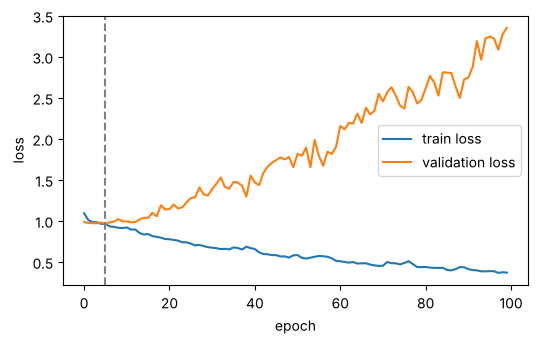

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot([h[0] for h in history], label="train loss")
ax.plot([h[1] for h in history], label="validation loss")
ax.axvline(best, color="grey", linestyle="--")
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.legend()
plt.show()

## Your turn

1. Change `hidden=128` to `hidden=8` and rerun. How do the two curves change?
2. Remove `model.eval()` and `torch.no_grad()` from the validation step. The numbers barely change here. Why would they change with a Dropout layer in the model?
3. Save the weights from the best epoch only, using `{k: v.clone() for k, v in model.state_dict().items()}` whenever the validation loss improves.